# Project Title - Telecom Customer Churn Analysis

## -->Business Object

##### The company's churn rate is about 13%, and the target is below 8%. 
##### This project builds a machine learning model to identify at-risk customers so the retention team can step in early.

## Load the data

In [81]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
try:
    df = pd.read_excel("Telecom_Project (1).xlsx")
    print("Excel file loaded successfully!")
except FileNotFoundError:
    print("Error: Excel file not found.please check the file path.")

Excel file loaded successfully!


In [82]:
df

,account_length,voice_mail_plan,voice_mail_messages,day_mins,evening_mins,night_mins,international_mins,customer_service_calls,international_plan,day_calls,day_charge,evening_calls,evening_charge,night_calls,night_charge,international_calls,international_charge,total_charge,churn
0,14,1,50,71.23,330.36,70.68,8.04,5,0,127,12.11,53,28.08,80,3.18,4,2.17,45.54,0
1,86,0,0,302.71,292.08,306.02,5.66,0,0,120,51.46,154,24.83,66,13.77,1,1.53,91.59,1
2,37,1,59,304.23,232.02,134.29,18.43,4,1,127,51.72,163,19.72,92,6.04,19,4.98,82.46,0
3,145,0,0,155.49,290.78,203.57,10.27,7,0,147,26.43,135,24.72,170,9.16,1,2.77,63.08,0
4,166,1,53,181.20,138.57,153.77,12.19,1,1,156,30.80,139,11.78,126,6.92,0,3.29,52.79,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,27,0,0,60.09,129.65,69.05,12.65,0,0,102,10.22,100,11.02,150,3.11,1,3.42,27.77,0
4996,190,1,22,172.86,188.59,256.96,14.99,2,0,63,29.39,102,16.03,91,11.56,19,4.05,61.03,0
4997,118,0,0,108.91,247.86,120.15,17.42,1,1,80,18.51,135,21.07,58,5.41,0,4.70,49.69,0
4998,133,0,0,156.21,349.00,255.49,14.74,5,0,142,26.56,75,29.67,41,11.50,16,3.98,71.71,0


In [18]:
df.head()

,account_length,voice_mail_plan,voice_mail_messages,day_mins,evening_mins,night_mins,international_mins,customer_service_calls,international_plan,day_calls,day_charge,evening_calls,evening_charge,night_calls,night_charge,international_calls,international_charge,total_charge,churn
0,14,1,50,71.23,330.36,70.68,8.04,5,0,127,12.11,53,28.08,80,3.18,4,2.17,45.54,0
1,86,0,0,302.71,292.08,306.02,5.66,0,0,120,51.46,154,24.83,66,13.77,1,1.53,91.59,1
2,37,1,59,304.23,232.02,134.29,18.43,4,1,127,51.72,163,19.72,92,6.04,19,4.98,82.46,0
3,145,0,0,155.49,290.78,203.57,10.27,7,0,147,26.43,135,24.72,170,9.16,1,2.77,63.08,0
4,166,1,53,181.20,138.57,153.77,12.19,1,1,156,30.80,139,11.78,126,6.92,0,3.29,52.79,0


In [19]:
df.shape

(5000, 19)

In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   account_length          5000 non-null   int64  
 1   voice_mail_plan         5000 non-null   int64  
 2   voice_mail_messages     5000 non-null   int64  
 3   day_mins                5000 non-null   float64
 4   evening_mins            5000 non-null   float64
 5   night_mins              5000 non-null   float64
 6   international_mins      5000 non-null   float64
 7   customer_service_calls  5000 non-null   int64  
 8   international_plan      5000 non-null   int64  
 9   day_calls               5000 non-null   int64  
 10  day_charge              5000 non-null   float64
 11  evening_calls           5000 non-null   int64  
 12  evening_charge          5000 non-null   float64
 13  night_calls             5000 non-null   int64  
 14  night_charge            5000 non-null   

In [21]:
df.describe()

,account_length,voice_mail_plan,voice_mail_messages,day_mins,evening_mins,night_mins,international_mins,customer_service_calls,international_plan,day_calls,day_charge,evening_calls,evening_charge,night_calls,night_charge,international_calls,international_charge,total_charge,churn
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,125.581000,0.355200,10.957000,183.857858,210.890544,202.101204,8.007194,3.490800,0.154200,104.087800,31.255900,104.941800,17.925798,104.945400,9.094556,10.053800,2.161972,60.438226,0.129800
std,71.337247,0.478622,18.059723,84.320279,87.720430,81.780639,4.864237,2.268864,0.361176,38.333421,14.334427,37.619344,7.456216,37.746822,3.680063,6.072815,1.313298,16.775478,0.336117
min,1.000000,0.000000,0.000000,40.030000,60.010000,60.090000,0.000000,0.000000,0.000000,40.000000,6.810000,40.000000,5.100000,40.000000,2.700000,0.000000,0.000000,18.570000,0.000000
25%,66.000000,0.000000,0.000000,109.090000,134.625000,130.547500,3.910000,2.000000,0.000000,70.000000,18.547500,73.000000,11.440000,73.000000,5.877500,5.000000,1.060000,47.860000,0.000000
50%,126.000000,0.000000,0.000000,182.190000,208.240000,203.425000,7.820000,4.000000,0.000000,104.000000,30.975000,105.000000,17.700000,104.000000,9.155000,10.000000,2.110000,60.605000,0.000000
75%,188.000000,1.000000,19.000000,257.422500,287.747500,274.642500,11.870000,5.000000,0.000000,137.000000,43.760000,137.000000,24.460000,138.000000,12.360000,15.000000,3.200000,72.972500,0.000000
max,250.000000,1.000000,60.000000,329.880000,359.960000,339.870000,21.970000,7.000000,1.000000,170.000000,56.080000,170.000000,30.600000,170.000000,15.290000,20.000000,5.930000,103.380000,1.000000


In [22]:
df.isnull().sum()

account_length            0
voice_mail_plan           0
voice_mail_messages       0
day_mins                  0
evening_mins              0
night_mins                0
international_mins        0
customer_service_calls    0
international_plan        0
day_calls                 0
day_charge                0
evening_calls             0
evening_charge            0
night_calls               0
night_charge              0
international_calls       0
international_charge      0
total_charge              0
churn                     0
dtype: int64

## Data quality checks

In [26]:
df.duplicated().sum()            # Expect 0

np.int64(0)

In [24]:
df.isnull().sum().sum()                 # Expect 0

np.int64(0)

In [25]:
df["churn"].value_counts(normalize=True)       # zero = Left the people, One = Stayed the people

churn
0    0.8702
1    0.1298
Name: proportion, dtype: float64

## Exploratory Data Analysis

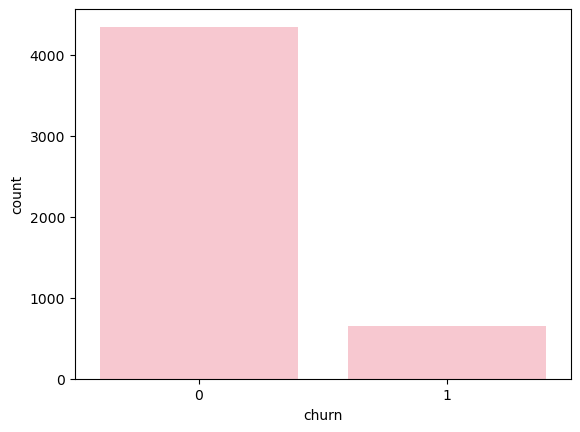

In [44]:
sns.countplot(x="churn", data=df,color="Pink"); plt.show()

##### 1. Most customers Stayed with the company.
##### 2. Few customers left,so churn reduction is important.

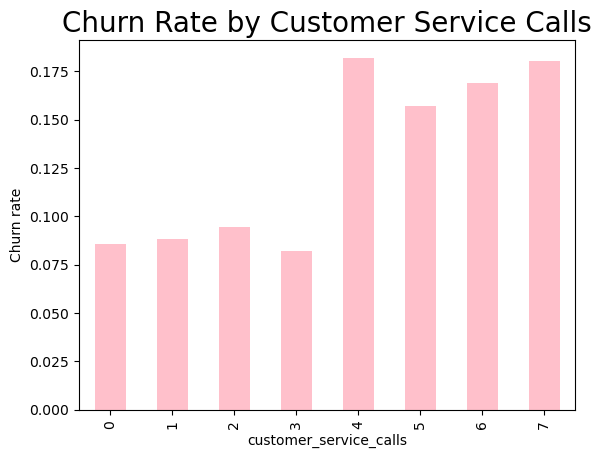

In [48]:
# Churn rate by customer service calls
try:
    df.groupby("customer_service_calls")["churn"].mean().plot(kind="bar",color="Pink")

    plt.ylabel("Churn rate")
    plt.title("Churn Rate by Customer Service Calls",fontsize="20")
    plt.show()

except KeyError as e:
    print(f"Error: Column not found - {e}")
except TypeError as e:
    print(f"Error: Invalid data type - {e}")

##### 1.Churn rates increase when custer service calls reach 4 or more.
##### 2.Customers making more service calls may br less satisfied.
##### 3.The company should to reduce churn.

In [51]:
#Churn rate By International Plan:
try:
    print("Churn Rate by International Plan:")                              # zero = Left the people, One = Stayed the people
    print(df.groupby("international_plan")["churn"].mean())

except KeyError as e:
    print(f"Error: Column not found - {e}")

except TypeError as e:
    print(f"Error: Invalid data type - {e}")

Churn Rate by International Plan:
international_plan
0    0.120359
1    0.181582
Name: churn, dtype: float64


In [50]:
# Churn rate by voice mail plan
try:
    print("\nChurn Rate by Voice Mail Plan:")
    print(df.groupby("voice_mail_plan")["churn"].mean())           # zero = Left the people, One = Stayed the people

except KeyError as e:
    print(f"Error: Column not found - {e}")

except TypeError as e:
    print(f"Error: Invalid data type - {e}")


Churn Rate by Voice Mail Plan:
voice_mail_plan
0    0.140509
1    0.110360
Name: churn, dtype: float64


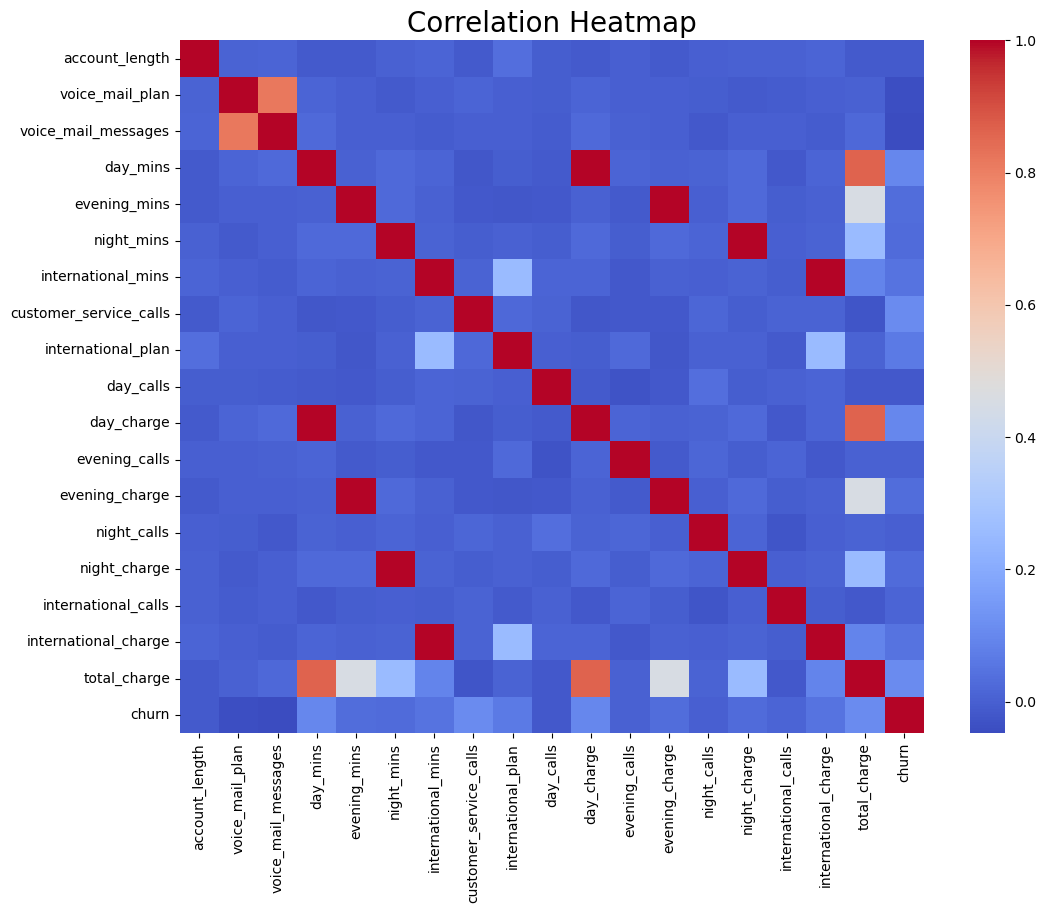

In [54]:
 # Correlation heatmap
try:
    plt.figure(figsize=(12, 9))

    sns.heatmap(
        df.corr(numeric_only=True),
        cmap="coolwarm",
        annot=False
    )
    plt.title("Correlation Heatmap",fontsize="20")
    plt.show()

except KeyError as e:
    print(f"Error: Column not found - {e}")
except TypeError as e:
    print(f"Error: Invalid data type - {e}")
except Exception as e:
    print(f"An unexpected error occurred: {e}")

#### * The heatmap shows strong correlations between call minutes and their corresponding charges.
#### * Voice mail plans are positively correlated with voice mail messages.
#### * Most features have weak correlations with customer churn.
#### * The company should focus on customer behavior and service quality to reduce churn.

## Feature Engineering And Cleaning

In [56]:
# charges are just minutes * 0.17, so drop the redundant ones
try:
    df_model = df.drop(
        columns=[
            "day_charge",
            "evening_charge",
            "night_charge",
            "international_charge"
        ]
    )

    print("Redundant charge columns dropped successfully!")
    print(df_model.head())

except KeyError as e:
    print(f"Error: Column not found - {e}")
except Exception as e:
    print(f"An unexpected error occurred: {e}")

Redundant charge columns dropped successfully!
   account_length  voice_mail_plan  voice_mail_messages  day_mins  \
0              14                1                   50     71.23   
1              86                0                    0    302.71   
2              37                1                   59    304.23   
3             145                0                    0    155.49   
4             166                1                   53    181.20   

   evening_mins  night_mins  international_mins  customer_service_calls  \
0        330.36       70.68                8.04                       5   
1        292.08      306.02                5.66                       0   
2        232.02      134.29               18.43                       4   
3        290.78      203.57               10.27                       7   
4        138.57      153.77               12.19                       1   

   international_plan  day_calls  evening_calls  night_calls  \
0                   0  

In [57]:
# New features:
try:
    df_model["total_mins"] = (
        df["day_mins"]
        + df["evening_mins"]
        + df["night_mins"]
        + df["international_mins"]
    )

    df_model["high_service_calls"] = (
        df["customer_service_calls"] >= 4
    ).astype(int)

    print("Feature engineering completed successfully!")
    print(df_model.head())

except KeyError as e:
    print(f"Error: Required column not found - {e}")
except TypeError as e:
    print(f"Error: Invalid data type - {e}")
except Exception as e:
    print(f"An unexpected error occurred: {e}")

Feature engineering completed successfully!
   account_length  voice_mail_plan  voice_mail_messages  day_mins  \
0              14                1                   50     71.23   
1              86                0                    0    302.71   
2              37                1                   59    304.23   
3             145                0                    0    155.49   
4             166                1                   53    181.20   

   evening_mins  night_mins  international_mins  customer_service_calls  \
0        330.36       70.68                8.04                       5   
1        292.08      306.02                5.66                       0   
2        232.02      134.29               18.43                       4   
3        290.78      203.57               10.27                       7   
4        138.57      153.77               12.19                       1   

   international_plan  day_calls  evening_calls  night_calls  \
0                   0     

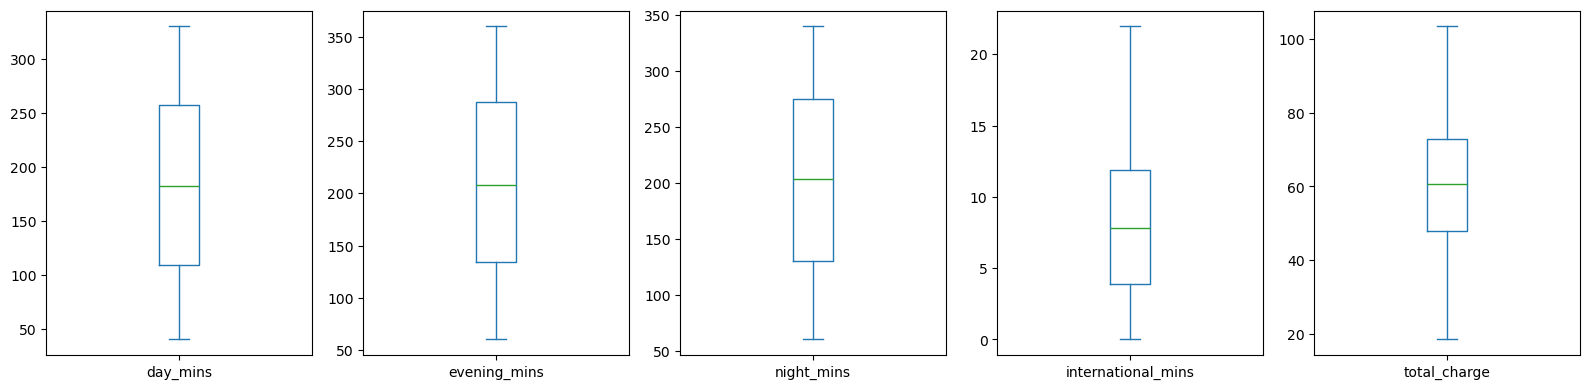

In [60]:
cols = ["day_mins", "evening_mins", "night_mins",
        "international_mins", "total_charge"]

df_model[cols].plot(kind="box", subplots=True, layout=(1, 5), figsize=(16,4))
plt.tight_layout()
plt.show()

## Train/Test Split and Scaling:

In [64]:
try:
    from sklearn.model_selection import train_test_split
    from sklearn.preprocessing import StandardScaler

                                                                    # (Separate features and target)
    X = df_model.drop("churn", axis=1)
    y = df_model["churn"]

                                                                      # (Split the dataset)
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.2,
        stratify=y,
        random_state=42
    )

                                                                    # (Standardize the features)
    scaler = StandardScaler()

    X_train_s = scaler.fit_transform(X_train)                        # Fit on training data only
    X_test_s = scaler.transform(X_test)                              # Transform test data

    print("Data splitting and scaling completed successfully!")
    print("Training data shape:", X_train_s.shape)
    print("Testing data shape:", X_test_s.shape)

except KeyError as e:
    print(f"Error: Required column not found - {e}")
except ValueError as e:
    print(f"Error: Unable to split or scale data - {e}")
except NameError as e:
    print(f"Error: DataFrame is not defined - {e}")

Data splitting and scaling completed successfully!
Training data shape: (4000, 16)
Testing data shape: (1000, 16)


## Train all 6 models:

In [69]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score)

spw = (y_train==0).sum()/(y_train==1).sum()
models = {
 "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
 "Decision Tree": DecisionTreeClassifier(max_depth=6, class_weight="balanced", random_state=42),
 "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42),
 "Gradient Boosting": GradientBoostingClassifier(random_state=42),
 "KNN": KNeighborsClassifier(),
 "SVC": SVC(probability=True, class_weight="balanced"),
}

results = []
for name, m in models.items():
    m.fit(X_train_s, y_train)
    pred = m.predict(X_test_s)
    prob = m.predict_proba(X_test_s)[:,1]
    results.append([name, accuracy_score(y_test,pred), precision_score(y_test,pred),
                    recall_score(y_test,pred), f1_score(y_test,pred),
                    roc_auc_score(y_test,prob)])

res = pd.DataFrame(results, columns=["Model","Accuracy","Precision","Recall","F1","ROC_AUC"])
res.sort_values("ROC_AUC", ascending=False)

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
3,Gradient Boosting,0.869,0.333333,0.007692,0.015038,0.657560
2,Random Forest,0.868,0.000000,0.000000,0.000000,0.647259
0,Logistic Regression,0.609,0.190024,0.615385,0.290381,0.641777
5,SVC,0.616,0.172680,0.515385,0.258687,0.618930
1,Decision Tree,0.624,0.181347,0.538462,0.271318,0.585150
4,KNN,0.858,0.250000,0.046154,0.077922,0.574187


In [71]:
try:
    from sklearn.linear_model import LogisticRegression
    from sklearn.tree import DecisionTreeClassifier
    from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
    from sklearn.neighbors import KNeighborsClassifier
    from sklearn.svm import SVC
    from sklearn.metrics import (
        accuracy_score, precision_score, recall_score,
        f1_score, roc_auc_score
    )

    # Models
    models = {
        "Logistic Regression": LogisticRegression(
            max_iter=1000, class_weight="balanced"
        ),
        "Decision Tree": DecisionTreeClassifier(
            max_depth=6, class_weight="balanced", random_state=42
        ),
        "Random Forest": RandomForestClassifier(
            n_estimators=300, class_weight="balanced", random_state=42
        ),
        "Gradient Boosting": GradientBoostingClassifier(random_state=42),
        "KNN": KNeighborsClassifier(),
        "SVC": SVC(probability=True, class_weight="balanced")
    }

    # Train models and evaluate performance
    results = []

    for name, model in models.items():
        model.fit(X_train_s, y_train)

        pred = model.predict(X_test_s)
        prob = model.predict_proba(X_test_s)[:, 1]

        results.append([
            name,
            accuracy_score(y_test, pred),
            precision_score(y_test, pred, zero_division=0),
            recall_score(y_test, pred, zero_division=0),
            f1_score(y_test, pred, zero_division=0),
            roc_auc_score(y_test, prob)
        ])

    # Create comparison DataFrame
    res = pd.DataFrame(
        results,
        columns=[
            "Model", "Accuracy", "Precision",
            "Recall", "F1", "ROC_AUC"
        ]
    )

    print("Model evaluation completed successfully!")
    print(res.sort_values("ROC_AUC", ascending=False))

except ImportError as e:
    print(f"Error: Required library not found - {e}")
except NameError as e:
    print(f"Error: Required variable is not defined - {e}")

Model evaluation completed successfully!
                 Model  Accuracy  Precision    Recall        F1   ROC_AUC
3    Gradient Boosting     0.869   0.333333  0.007692  0.015038  0.657560
2        Random Forest     0.868   0.000000  0.000000  0.000000  0.647259
0  Logistic Regression     0.609   0.190024  0.615385  0.290381  0.641777
5                  SVC     0.616   0.172680  0.515385  0.258687  0.618886
1        Decision Tree     0.624   0.181347  0.538462  0.271318  0.585150
4                  KNN     0.858   0.250000  0.046154  0.077922  0.574187


## Evaluate the best model:

              precision    recall  f1-score   support

           0       0.87      1.00      0.93       870
           1       0.00      0.00      0.00       130

    accuracy                           0.87      1000
   macro avg       0.43      0.50      0.46      1000
weighted avg       0.76      0.87      0.81      1000



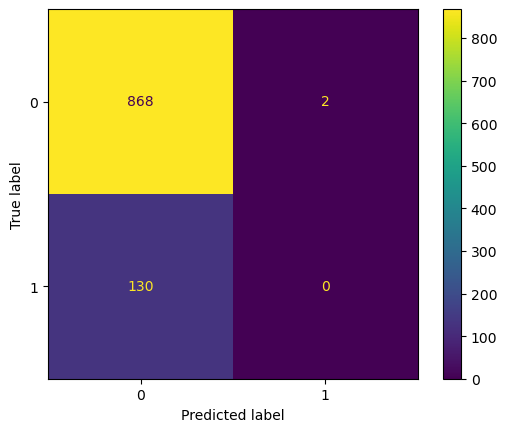

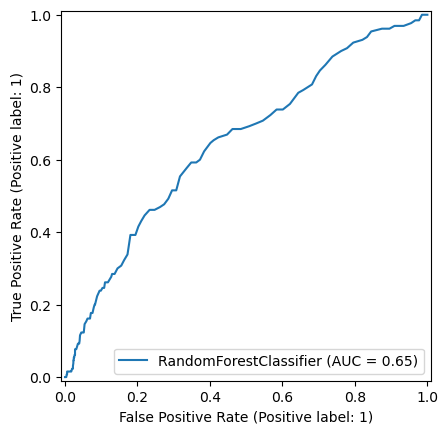

In [72]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay, classification_report
best = models["Random Forest"]                                   # replace with your top model from the table
pred = best.predict(X_test_s)
print(classification_report(y_test, pred))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred)).plot()
RocCurveDisplay.from_estimator(best, X_test_s, y_test); plt.show()

## Improve with cross-validation and tuning

In [76]:
from sklearn.model_selection import GridSearchCV
grid = GridSearchCV(RandomForestClassifier(class_weight="balanced", random_state=42),
    {"n_estimators":[200,400], "max_depth":[6,10,None], "min_samples_leaf":[1,5]},
    scoring="roc_auc", cv=5, n_jobs=-1)
grid.fit(X_train_s, y_train)
print(grid.best_params_, grid.best_score_)

{'max_depth': 6, 'min_samples_leaf': 5, 'n_estimators': 400} 0.6529481465201183


## Turn predictions into action

In [77]:
final = grid.best_estimator_
test_out = X_test.copy()
test_out["churn_probability"] = final.predict_proba(X_test_s)[:,1]
test_out["risk"] = pd.cut(test_out["churn_probability"], [0,.3,.6,1],
                          labels=["Low","Medium","High"])
test_out.sort_values("churn_probability", ascending=False).head(20)

,account_length,voice_mail_plan,voice_mail_messages,day_mins,evening_mins,night_mins,international_mins,customer_service_calls,international_plan,day_calls,evening_calls,night_calls,international_calls,total_charge,total_mins,high_service_calls,churn_probability,risk
4819,50,0,0,305.14,273.88,213.10,11.83,6,0,63,56,104,3,87.93,803.95,1,0.746625,High
994,151,0,0,284.43,244.46,284.58,6.58,4,0,57,146,91,3,83.72,820.05,1,0.743673,High
1229,147,0,0,278.42,230.23,298.31,3.24,6,0,72,93,105,17,81.19,810.20,1,0.726449,High
1728,227,1,15,296.20,250.85,171.26,14.85,5,0,72,99,92,19,83.39,733.16,1,0.720567,High
1752,101,0,0,310.01,219.86,192.61,14.18,4,0,47,72,159,5,83.89,736.66,1,0.716183,High
673,180,0,0,320.26,177.77,197.85,12.46,6,0,77,122,72,7,81.81,708.34,1,0.700732,High
1611,70,1,5,298.98,145.81,288.59,8.56,7,0,85,122,131,15,78.52,741.94,1,0.689412,High
161,198,0,0,273.85,278.53,215.05,13.89,5,0,51,149,70,15,83.66,781.32,1,0.688436,High
467,44,0,0,314.33,358.82,132.74,11.69,6,0,87,119,134,0,93.07,817.58,1,0.680737,High
935,140,0,0,325.95,144.35,316.51,12.42,5,0,52,76,89,6,85.27,799.23,1,0.680235,High


##### *Call high-risk customers who have 4 or more service calls, and fix their issues first.
##### *Offer discounted plans to heavy day-time users with high total charges.
##### *Review pricing for international plan customers.
##### *Promote the voice mail plan, since those customers churn less.

## Save the model:

In [80]:
import joblib
joblib.dump(final, "churn_model.pkl")
joblib.dump(scaler, "scaler.pkl")

['scaler.pkl']

# Project Insights

## Overall churn
##### 1.13% of customers churned (649 of 5,000).
##### 2.Their billing was about $42K, or 14% of total revenue.

## Customer service calls (strongest signal)
##### 1.4+ calls: 17.2% churn. 0–3 calls: 8.8% churn. That is about 2x the risk.
##### 2.Churn does not rise slowly. It jumps at the 4th call.

## Usage and billing
##### 1.Top-quartile daytime minutes users churn at 20.3%, against 10.5% for the rest.
##### 2.Top-quartile total charge churns at 21.0%, against about 10% in the other three quartiles.

## Plans
##### 1.International plan: 18.2% churn, against 12.0% without it.
##### 2.Voice mail plan: 11.0% churn, against 14.1% without it.

## Account length
##### 1.It has almost no effect. Churn stays between 12% and 14% across all tenure groups.

## Combined risk (highest-risk segments)
##### 1.4+ calls and heavy daytime use: 25.4% churn, about 4x the lowest-risk group (6.4%).
##### 2.International plan and 4+ calls: 23.6% churn.

## Business rules check
##### 1.All four rules in your sheet are supported by the data.

## Model insights
##### 1.Predictive power is modest, with ROC-AUC around 0.58 to 0.66.
##### 2.Accuracy is misleading because of the imbalance. Random Forest scored 86.8% accuracy but caught 0 churners.
##### 3.Logistic Regression was the most useful, with about 62% recall.

## Recommendations
##### 1.Trigger proactive outreach at the 4th service call.
##### 2.Prioritize customers with 4+ calls who are also heavy daytime users or international plan holders.
##### 3.Review pricing for high-bill and international customers.
##### 4.Promote the voice mail plan as a retention add-on.

